In [179]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
%load_ext autoreload
%autoreload 2

import numpy as np
import time
from src.experiments import (stat_vs_params, calculate_variance)
from src.functions import (calculate_barlet_values, get_sin_signal, get_impulse_signal, calculate_stiring_matrix, calculate_complex_stiring_matrix, calculate_full_barlet_values,
                           calculate_spectrum_energy, calculate_spectrum_SNR, calculate_noise_level,get_noise, get_avp_signals, calculate_energy, calculate_fft)

from src.configs.config import init_rng, restart_rng
import src.configs.config as cfg
import src.configs.comon as comon
from src.plotting import plot_variance_vs_param, plot_mean_vs_param, create_config_table
import os
origin_config = init_rng()

path = "attachment/images/report"
os.makedirs(path,exist_ok=True)






The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


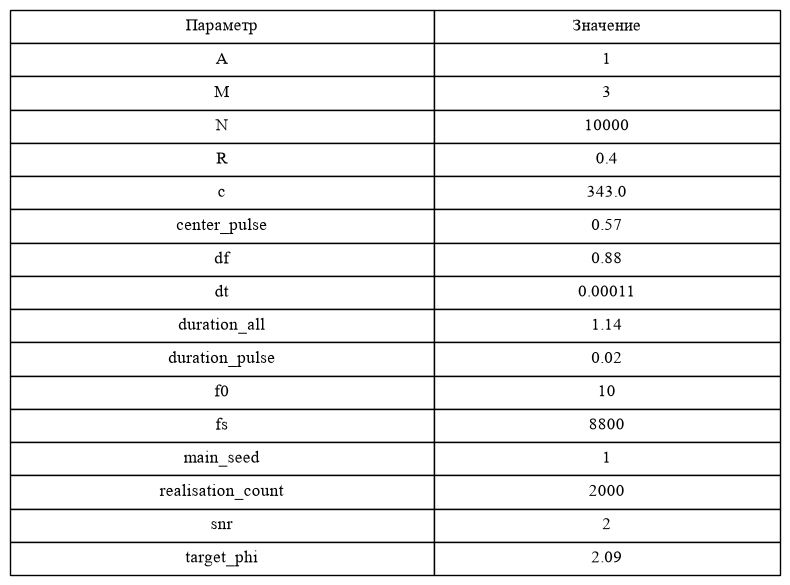

In [180]:
create_config_table(origin_config)
df = origin_config["df"]




In [181]:

def calculate_snr_values(config_params: dict,
                         start_snr: int | float,
                         freq_range: np.ndarray) -> np.ndarray:  # noqa: PYI041
    
    config_params["snr"] = start_snr
    pulse_signal = get_impulse_signal(config_params)
    energy_signal = calculate_energy(pulse_signal, config_params["time_vector"])
    noise = get_noise(config_params, np.random.default_rng(config_params["main_seed"]), energy_signal)
    snr_values = np.array([calculate_spectrum_SNR(pulse_signal, noise, config_params["freq_vector"], fr) for fr in freq_range])

    return snr_values

def calculate_target_idx(config_params: dict,
                         freq_range: np.ndarray,
                         start_snr: int | float,
                         threshold_snr: int | float) -> int | float:
    
    snr_values = np.array(calculate_snr_values(config_params,start_snr, freq_range))

    idx = np.argmin(np.abs(snr_values - threshold_snr))
    return idx



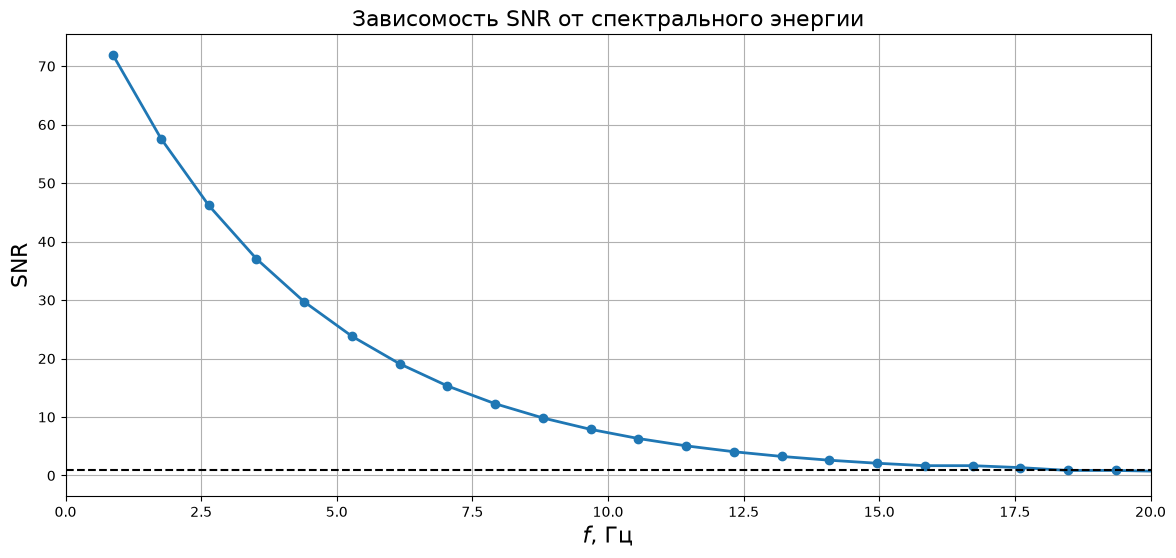

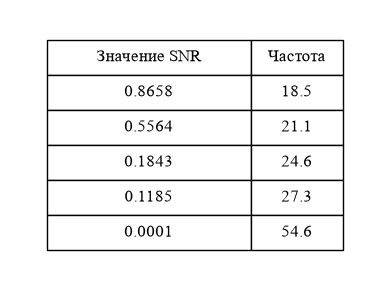

In [182]:
from matplotlib import pyplot as plt
from src.configs.config import FREQ_VALUES
from src.plotting import create_and_save_table
full_snr = 100
freq_range = np.arange(df, 1001*df, df)
origin_config["snr"] = full_snr

snr_values = calculate_snr_values(config_params =  origin_config,
                                  start_snr = full_snr,
                                  freq_range = freq_range)

idxs = [calculate_target_idx(config_params = origin_config,
                           freq_range = freq_range,
                           start_snr = full_snr,
                           threshold_snr = snr
                           ) for snr in (1, 0.5, 0.2,0.1, 0.0001)]

fig, ax = plt.subplots(1,1, figsize = (14,6))

ax.plot(freq_range, snr_values, marker = "o", linewidth = 2)
ax.set_title("Зависомость SNR от спектрального энергии", fontsize = 16)
ax.set_xlabel("$f$, Гц", fontsize = 16)
ax.set_ylabel("SNR", fontsize = 16)
ax.grid(True)
ax.set_xlim(0,20)
ax.axhline(snr_values[idxs[0]], color = "black", linestyle = "--")

rows = [
    [f"{snr_values[idx]:.4f}", f"{np.array(freq_range)[idx]:.1f}"]
    for idx in idxs]
create_and_save_table(rows = rows,
                      columns = ["Значение SNR", "Частота"],
                      filename = " ",
                      save = False)

(7.0, 50.0)

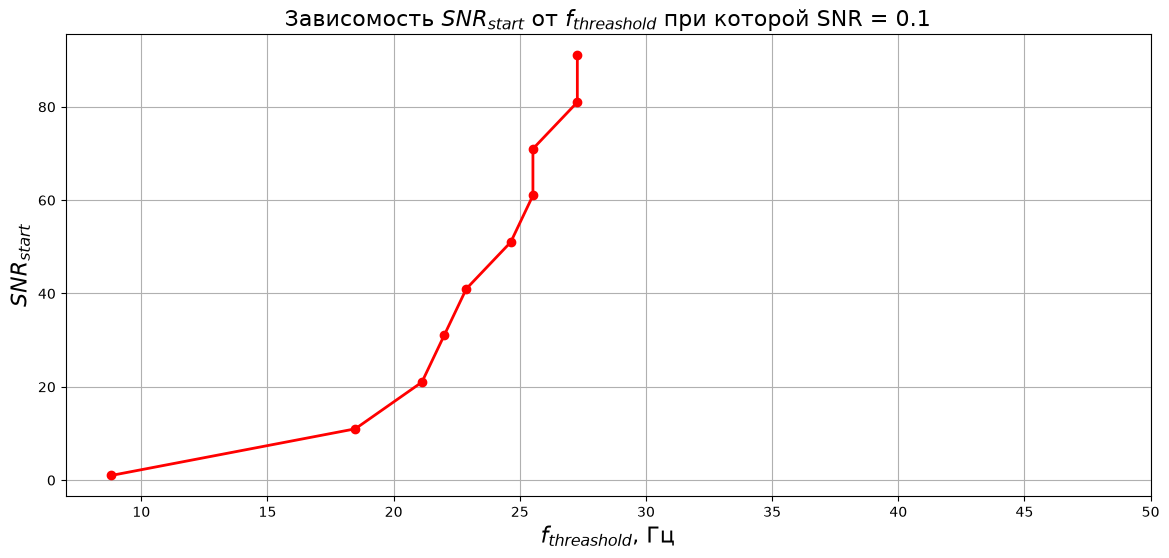

In [189]:
"""Меняем стартовый SNR и смотрим как меняется частота при которой SNR = 1"""
threshold = 0.1
start_snrs = np.arange(1,101,10)
idxs = [calculate_target_idx(config_params = origin_config,
                           freq_range = freq_range,
                           start_snr = snr ,
                           threshold_snr = threshold
                           ) for snr in start_snrs]
freqs = [freq_range[idx] for idx in idxs]
fig, ax = plt.subplots(1,1, figsize = (14,6))

ax.plot(freqs, start_snrs, marker = "o", linewidth = 2, color = 'red')
ax.set_title("Зависомость " + r"$SNR_{start}$ от "+ "$f_{threashold}$"+f" при которой SNR = {threshold}", fontsize = 16)
ax.set_xlabel("$f_{threashold}$, Гц", fontsize = 16)
ax.set_ylabel("$SNR_{start}$", fontsize = 16)
ax.grid(True)
ax.set_xlim(7,50)
